In [ ]:


import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

# Plot Settings
plt.style.use("seaborn-v0_8")
sns.set_palette("Set2")

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("johnsmith88/heart-disease-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'heart-disease-dataset' dataset.
Path to dataset files: /kaggle/input/heart-disease-dataset


In [ ]:


files = os.listdir(path)

print("Files in Dataset Folder:\n")

for file in files:
    print(file)

Files in Dataset Folder:

heart.csv


In [ ]:


df = pd.read_csv(os.path.join(path, "heart.csv"))

# First Five Rows
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
print("="*60)
print("DATASET OVERVIEW")
print("="*60)

print("Shape of Dataset :", df.shape)

print("\nRows :", df.shape[0])
print("Columns :", df.shape[1])

DATASET OVERVIEW
Shape of Dataset : (1025, 14)

Rows : 1025
Columns : 14


In [ ]:
print(df.columns.tolist())

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [ ]:
print(df.dtypes)

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


In [ ]:
print(df.dtypes)

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


In [ ]:
print(df.isnull().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


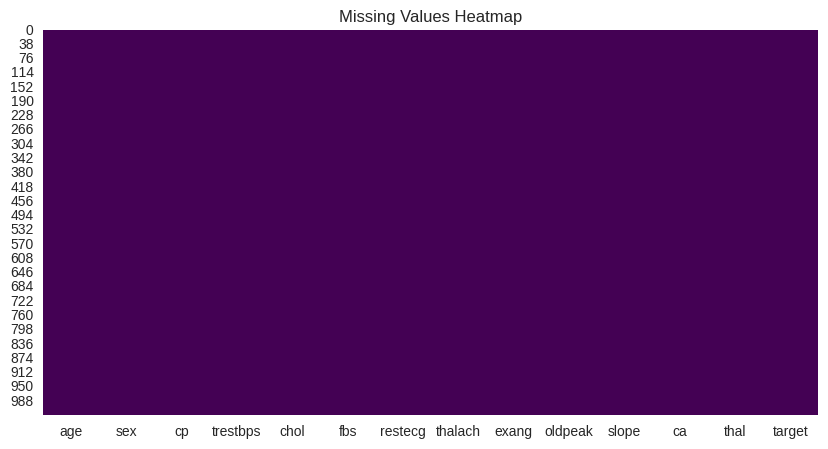

In [ ]:
plt.figure(figsize=(10,5))

sns.heatmap(df.isnull(),
            cbar=False,
            cmap="viridis")

plt.title("Missing Values Heatmap")
plt.show()

In [ ]:
# Number of Missing Values

df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)

In [ ]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

In [ ]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
print("Duplicate Rows :", df.duplicated().sum())

Duplicate Rows : 723


In [ ]:
df = df.drop_duplicates()

print("New Shape :", df.shape)

New Shape : (302, 14)


In [ ]:
categorical_columns = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal",
    "target"
]

for col in categorical_columns:
    df[col] = df[col].astype("category")

In [ ]:
df.dtypes

,0
age,int64
sex,category
cp,category
trestbps,int64
chol,int64
fbs,category
restecg,category
thalach,int64
exang,category
oldpeak,float64


In [ ]:
numerical_columns = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

df[numerical_columns].describe()

,age,trestbps,chol,thalach,oldpeak
count,302.00000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,131.602649,246.500000,149.569536,1.043046
std,9.04797,17.563394,51.753489,22.903527,1.161452
min,29.00000,94.000000,126.000000,71.000000,0.000000
25%,48.00000,120.000000,211.000000,133.250000,0.000000
50%,55.50000,130.000000,240.500000,152.500000,0.800000
75%,61.00000,140.000000,274.750000,166.000000,1.600000
max,77.00000,200.000000,564.000000,202.000000,6.200000


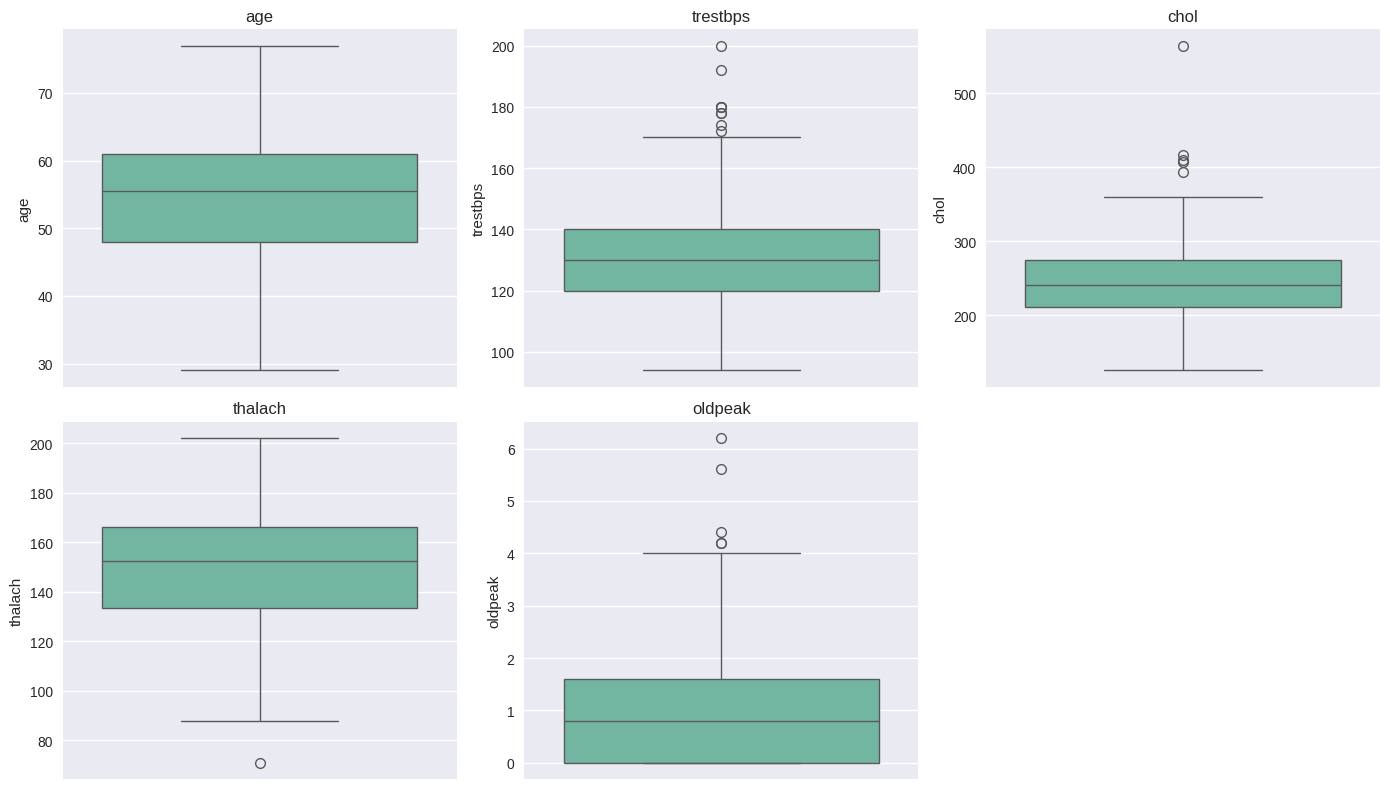

In [ ]:
plt.figure(figsize=(14,8))

for i,col in enumerate(numerical_columns):

    plt.subplot(2,3,i+1)

    sns.boxplot(y=df[col])

    plt.title(col)

plt.tight_layout()
plt.show()

In [ ]:
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    df[col] = np.where(df[col] < lower,
                       lower,
                       df[col])

    df[col] = np.where(df[col] > upper,
                       upper,
                       df[col])

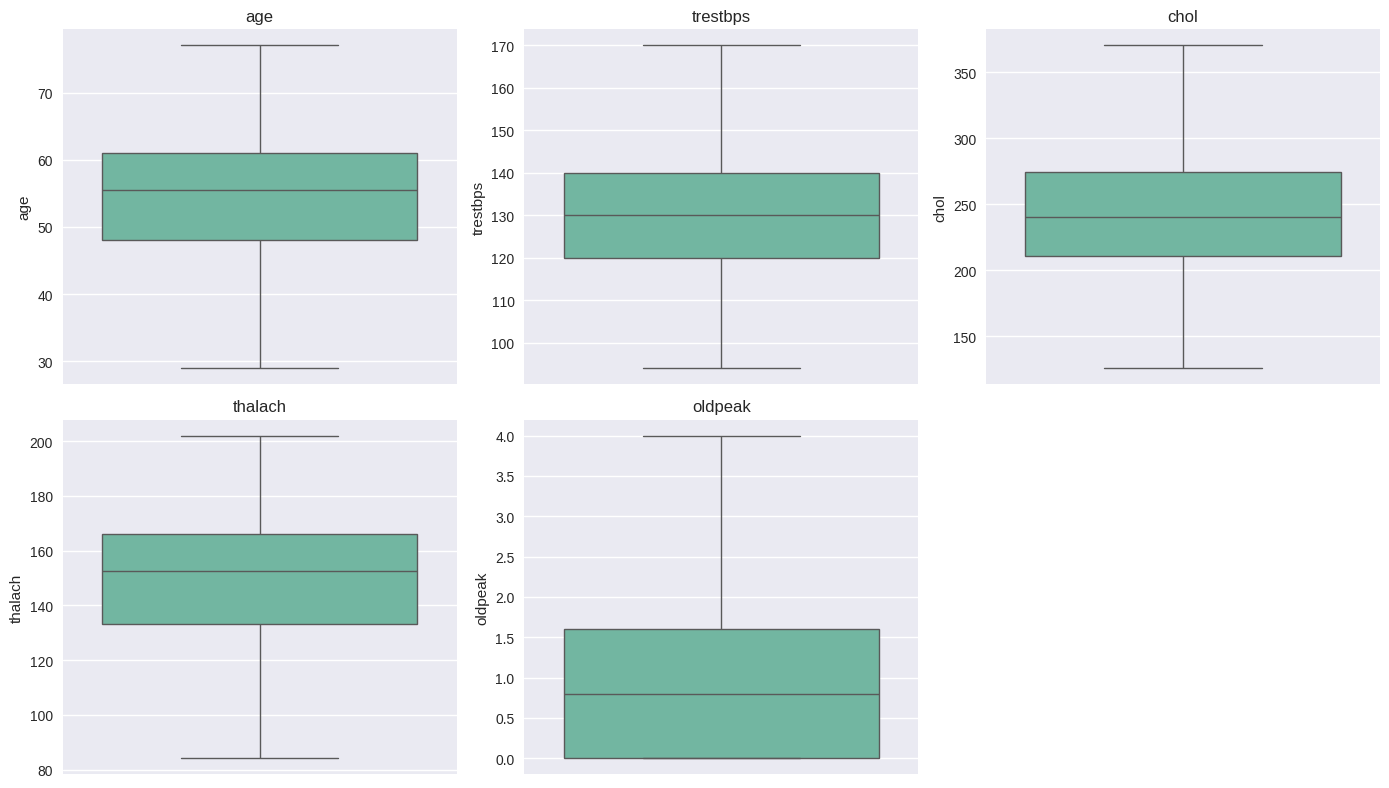

In [ ]:
plt.figure(figsize=(14,8))

for i,col in enumerate(numerical_columns):

    plt.subplot(2,3,i+1)

    sns.boxplot(y=df[col])

    plt.title(col)

plt.tight_layout()
plt.show()

In [ ]:
scaler = StandardScaler()

df[numerical_columns] = scaler.fit_transform(df[numerical_columns])

In [ ]:
df[numerical_columns].head()

,age,trestbps,chol,thalach,oldpeak
0,-0.267966,-0.377511,-0.704039,0.808993,-0.025091
1,-0.157260,0.527318,-0.893880,0.237018,1.869266
2,1.724733,0.828927,-1.505591,-1.082925,1.418229
3,0.728383,1.009893,-0.893880,0.501006,-0.927166
4,0.839089,0.406674,1.025627,-1.918889,0.786777


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 302 entries, 0 to 878
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       302 non-null    float64 
 1   sex       302 non-null    category
 2   cp        302 non-null    category
 3   trestbps  302 non-null    float64 
 4   chol      302 non-null    float64 
 5   fbs       302 non-null    category
 6   restecg   302 non-null    category
 7   thalach   302 non-null    float64 
 8   exang     302 non-null    category
 9   oldpeak   302 non-null    float64 
 10  slope     302 non-null    category
 11  ca        302 non-null    category
 12  thal      302 non-null    category
 13  target    302 non-null    category
dtypes: category(9), float64(5)
memory usage: 18.2 KB
None


In [ ]:
df.to_csv("heart_disease_cleaned.csv", index=False)

print("Cleaned Dataset Saved Successfully!")

Cleaned Dataset Saved Successfully!


In [ ]:
print("="*50)
print("FINAL DATA QUALITY REPORT")
print("="*50)

print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Rows")
print(df.duplicated().sum())

print("\nData Types")
print(df.dtypes)

print("\nSummary Statistics")
print(df.describe(include="all"))

FINAL DATA QUALITY REPORT
Rows : 302
Columns : 14

Missing Values
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate Rows
0

Data Types
age          float64
sex         category
cp          category
trestbps     float64
chol         float64
fbs         category
restecg     category
thalach      float64
exang       category
oldpeak      float64
slope       category
ca          category
thal        category
target      category
dtype: object

Summary Statistics
                 age    sex     cp      trestbps          chol    fbs  \
count   3.020000e+02  302.0  302.0  3.020000e+02  3.020000e+02  302.0   
unique           NaN    2.0    4.0           NaN           NaN    2.0   
top              NaN    1.0    0.0           NaN           NaN    0.0   
freq             NaN  206.0  143.0           NaN           NaN  257.0   
me

In [ ]:
# Average Age

average_age = df["age"].mean()

print(f"Average Age of Patients: {average_age:.2f} years")

Average Age of Patients: -0.00 years


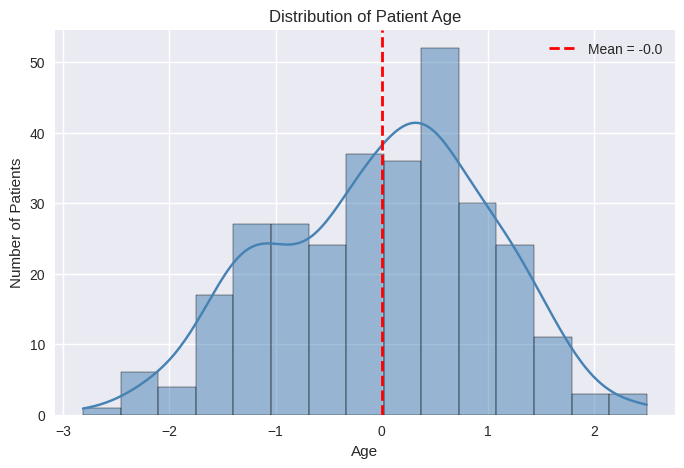

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["age"],
             bins=15,
             kde=True,
             color="steelblue")

plt.axvline(average_age,
            color="red",
            linestyle="--",
            linewidth=2,
            label=f"Mean = {average_age:.1f}")

plt.title("Distribution of Patient Age")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.legend()

plt.show()

Insight
Most patients belong to the middle-age category.
The average age indicates the typical patient profile.
Business Impact

Healthcare providers can focus preventive screening programs on middle-aged adults to reduce future cardiovascular complications.

In [ ]:
gender_count = df["sex"].value_counts()

print(gender_count)

sex
1    206
0     96
Name: count, dtype: int64


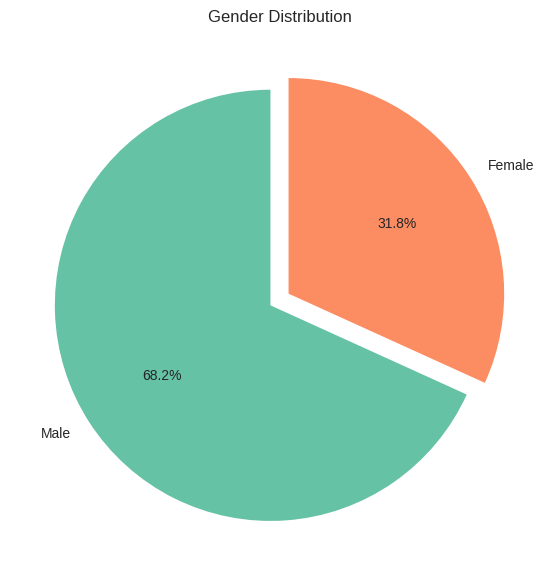

In [ ]:
gender_labels = ["Male","Female"]

plt.figure(figsize=(7,7))

plt.pie(gender_count,
        labels=gender_labels,
        autopct="%1.1f%%",
        startangle=90,
        explode=(0.05,0.05))

plt.title("Gender Distribution")

plt.show()

Insight
Compare the percentage of male and female patients.
Identify whether one gender dominates the dataset.
Business Impact

Gender-based awareness campaigns can improve targeted healthcare strategies.

In [ ]:
average_bp = df["trestbps"].mean()

print(f"Average Resting Blood Pressure: {average_bp:.2f}")

Average Resting Blood Pressure: 0.00


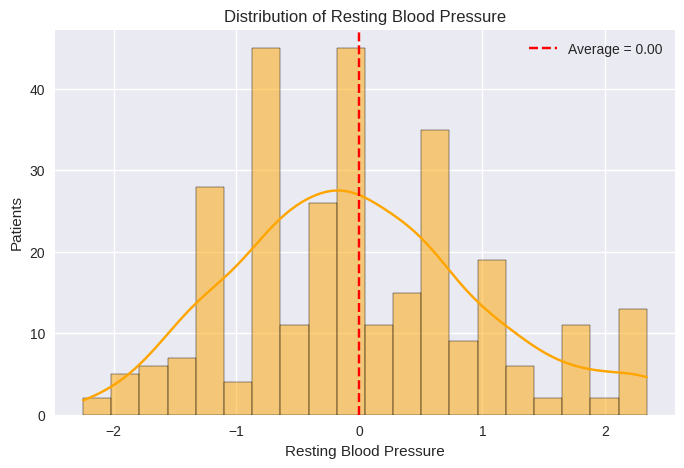

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["trestbps"],
             bins=20,
             kde=True,
             color="orange")

plt.axvline(average_bp,
            color="red",
            linestyle="--",
            label=f"Average = {average_bp:.2f}")

plt.title("Distribution of Resting Blood Pressure")
plt.xlabel("Resting Blood Pressure")
plt.ylabel("Patients")

plt.legend()

plt.show()

Insight
Most patients cluster around the average blood pressure.
Extremely high values may indicate hypertension risk.
Business Impact

Patients with elevated blood pressure should be prioritized for regular monitoring and lifestyle interventions.

In [ ]:
print(df["fbs"].dtype)
print(df["fbs"].unique())

category
[0, 1]
Categories (2, int64): [0, 1]


In [ ]:
high_fbs = (df["fbs"] == 1).sum()

print("Patients with High Fasting Blood Sugar:", high_fbs)

Patients with High Fasting Blood Sugar: 45


In [ ]:
print(df["fbs"].dtype)
print(df["fbs"].head())
print(df["fbs"].unique())

category
0    0
1    1
2    0
3    0
4    1
Name: fbs, dtype: category
Categories (2, int64): [0, 1]
[0, 1]
Categories (2, int64): [0, 1]


In [ ]:
cp_count = df["cp"].value_counts().sort_index()

print(cp_count)

cp
0    143
1     50
2     86
3     23
Name: count, dtype: int64


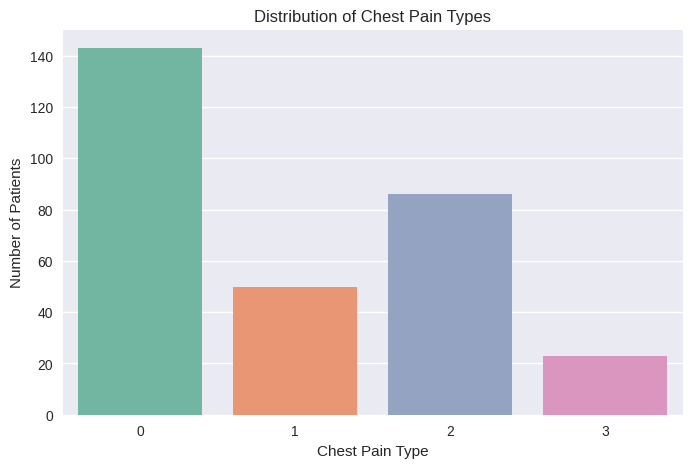

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="cp",
    data=df,
    palette="Set2"
)

plt.title("Distribution of Chest Pain Types")
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Patients")

plt.show()

Insight
Chest pain type frequencies help identify the most common clinical presentation.
Some chest pain categories are more strongly associated with heart disease.
Business Impact

Understanding chest pain patterns supports faster triage, improved diagnosis, and better allocation of healthcare resources.

In [ ]:
max_hr = df["thalach"].max()

print(f"Maximum Heart Rate Achieved: {max_hr}")

Maximum Heart Rate Achieved: 2.3049280475503133


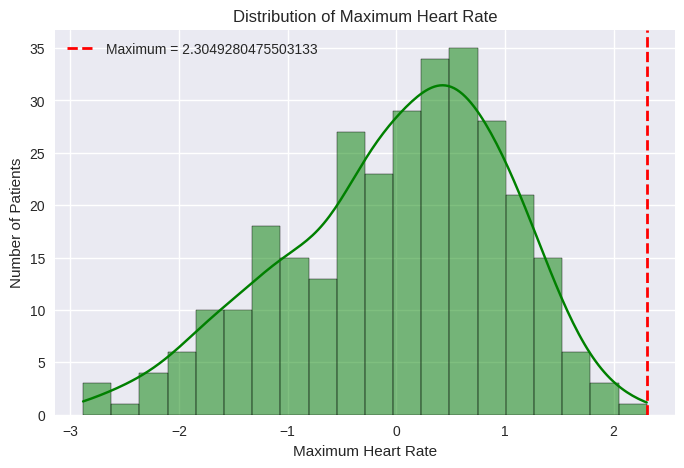

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["thalach"],
             bins=20,
             kde=True,
             color="green")

plt.axvline(max_hr,
            color="red",
            linestyle="--",
            linewidth=2,
            label=f"Maximum = {max_hr}")

plt.title("Distribution of Maximum Heart Rate")
plt.xlabel("Maximum Heart Rate")
plt.ylabel("Number of Patients")
plt.legend()

plt.show()

Insight
Most patients achieved moderate heart rates during exercise.
A few patients reached exceptionally high maximum heart rates.
Business Impact

Maximum heart rate helps physicians evaluate cardiovascular fitness and design safe rehabilitation programs.

In [ ]:
angina_percent = (df["exang"] == 1).mean() * 100

print(f"Exercise-Induced Angina: {angina_percent:.2f}%")

Exercise-Induced Angina: 32.78%


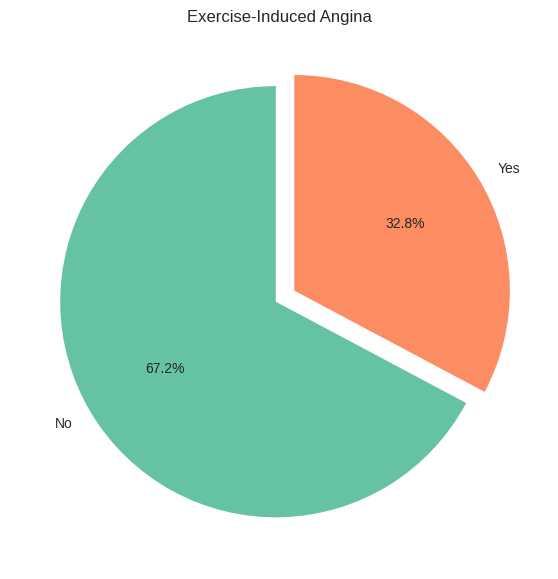

In [ ]:
angina = df["exang"].value_counts().sort_index()

plt.figure(figsize=(7,7))

plt.pie(
    angina,
    labels=["No","Yes"],
    autopct="%1.1f%%",
    startangle=90,
    explode=(0.02,0.08)
)

plt.title("Exercise-Induced Angina")

plt.show()

Insight
This KPI shows how many patients experience chest pain during exercise.
Exercise-induced angina is an important clinical indicator of coronary artery disease.
Business Impact

Patients with exercise-induced angina should receive personalized exercise recommendations and closer cardiac monitoring.

In [ ]:
average_chol = df["chol"].mean()

print(f"Average Cholesterol Level: {average_chol:.2f}")

Average Cholesterol Level: -0.00


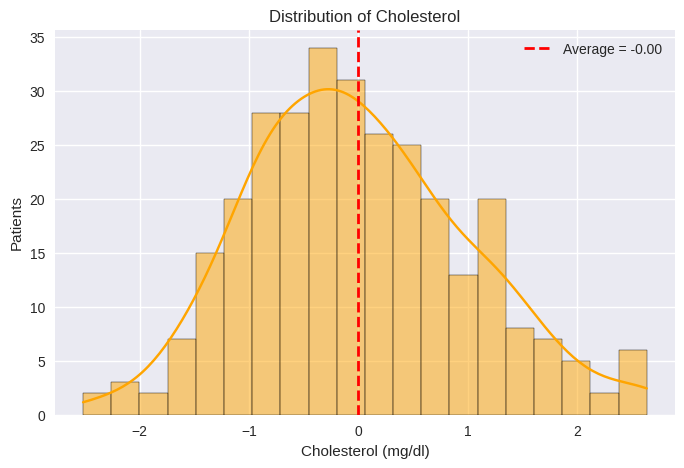

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["chol"],
             bins=20,
             kde=True,
             color="orange")

plt.axvline(average_chol,
            color="red",
            linestyle="--",
            linewidth=2,
            label=f"Average = {average_chol:.2f}")

plt.title("Distribution of Cholesterol")
plt.xlabel("Cholesterol (mg/dl)")
plt.ylabel("Patients")

plt.legend()

plt.show()

Insight
Cholesterol values vary considerably among patients.
Individuals with elevated cholesterol are generally at greater cardiovascular risk.
Business Impact

Regular cholesterol screening and personalized nutrition plans can reduce long-term heart disease risk.

In [ ]:
restecg_2 = (df["restecg"] == 2).sum()

print("Patients with Rest ECG = 2 :", restecg_2)

Patients with Rest ECG = 2 : 4


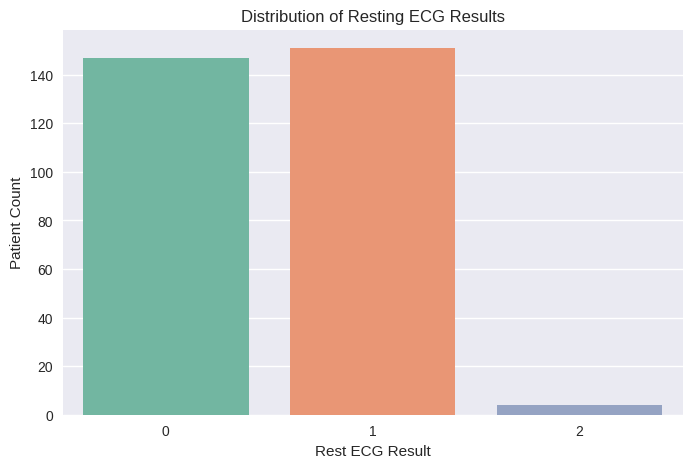

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="restecg",
    data=df,
    palette="Set2"
)

plt.title("Distribution of Resting ECG Results")
plt.xlabel("Rest ECG Result")
plt.ylabel("Patient Count")

plt.show()

Insight
ECG category 2 represents a specific cardiac abnormality.
Comparing ECG groups helps identify patients requiring further examination.
Business Impact

Patients with abnormal ECG findings can be prioritized for advanced cardiac testing and specialist consultations.

In [ ]:
ca_distribution = df["ca"].value_counts().sort_index()

print(ca_distribution)

ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64


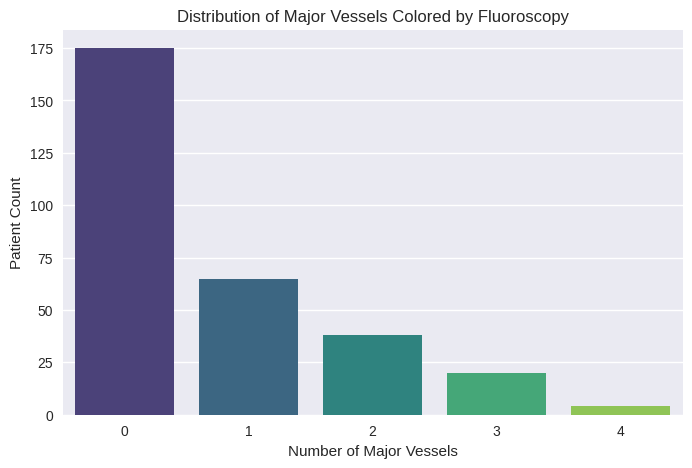

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="ca",
    data=df,
    palette="viridis"
)

plt.title("Distribution of Major Vessels Colored by Fluoroscopy")
plt.xlabel("Number of Major Vessels")
plt.ylabel("Patient Count")

plt.show()

Insight
Most patients have fewer affected vessels, while a smaller group has multiple affected vessels.
An increasing number of affected vessels generally indicates more severe coronary artery disease.
Business Impact

Patients with multiple blocked vessels may require priority treatment, intensive monitoring, and possible surgical intervention.

In [ ]:
correlation = df[["age", "chol"]].corr()

print(correlation)

           age      chol
age   1.000000  0.198901
chol  0.198901  1.000000


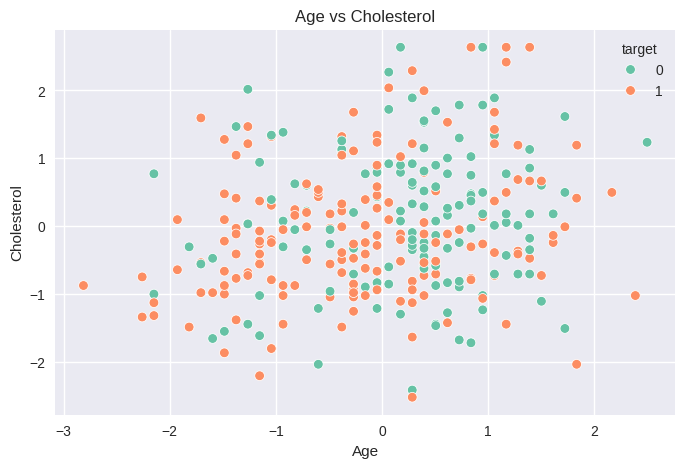

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x="age",
    y="chol",
    data=df,
    hue="target"
)

plt.title("Age vs Cholesterol")
plt.xlabel("Age")
plt.ylabel("Cholesterol")

plt.show()

Insight
Determines whether cholesterol increases with age.
Positive correlation suggests older patients tend to have higher cholesterol.
Business Impact

Healthcare providers can schedule cholesterol screenings more frequently for older adults.

In [ ]:
df["Age Group"] = pd.cut(
    df["age"],
    bins=[20,40,50,60,80],
    labels=["20-40","41-50","51-60","61+"]
)

In [ ]:
print(df["age"].head())
print(df["age"].min(), df["age"].max())

0   -0.267966
1   -0.157260
2    1.724733
3    0.728383
4    0.839089
Name: age, dtype: float64
-2.8141917242401924 2.4996708828440624


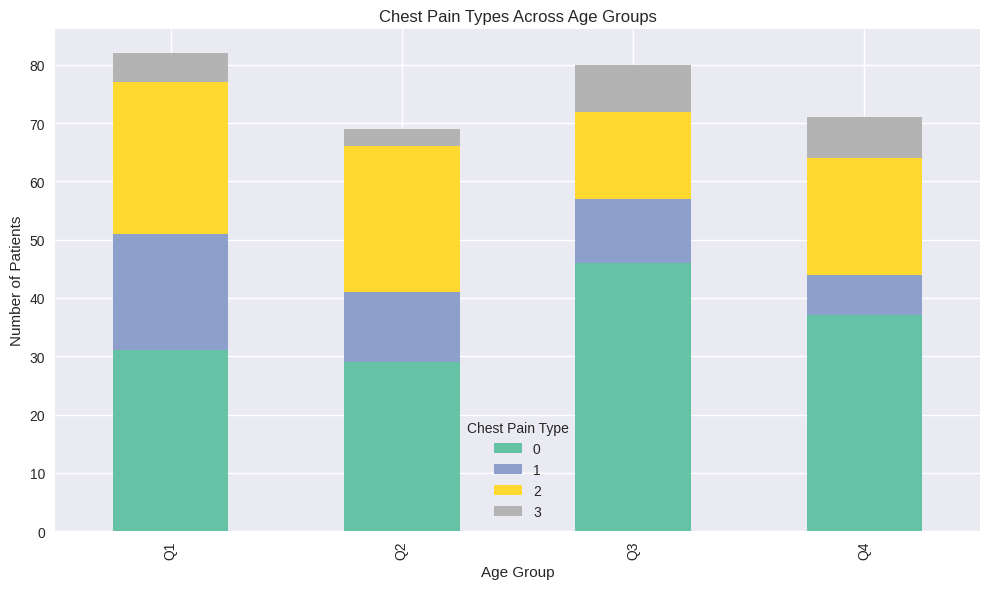

In [ ]:
# Create Age Groups (works for both original and normalized data)
if df["age"].min() >= 20:
    df["Age Group"] = pd.cut(
        df["age"],
        bins=[20, 40, 50, 60, 80],
        labels=["20-40", "41-50", "51-60", "61-80"],
        include_lowest=True
    )
else:
    df["Age Group"] = pd.qcut(
        df["age"],
        q=4,
        labels=["Q1", "Q2", "Q3", "Q4"],
        duplicates="drop"
    )

# Remove missing values if any
plot_df = df.dropna(subset=["Age Group", "cp"])

# Create crosstab
cp_age = pd.crosstab(plot_df["Age Group"], plot_df["cp"])

# Plot
cp_age.plot(kind="bar", stacked=True, figsize=(10,6), colormap="Set2")
plt.title("Chest Pain Types Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")
plt.legend(title="Chest Pain Type")
plt.tight_layout()
plt.show()

In [ ]:
print(df.dtypes)

age           float64
sex          category
cp           category
trestbps      float64
chol          float64
fbs          category
restecg      category
thalach       float64
exang        category
oldpeak       float64
slope        category
ca           category
thal         category
target       category
Age Group    category
dtype: object


In [ ]:
df["Age Group"] = pd.cut(
    df["age"],
    bins=[20,40,50,60,80],
    labels=["20-40","41-50","51-60","61+"]
)

In [ ]:
avg_hr = df.groupby("exang")["thalach"].mean()

print(avg_hr)

exang
0    0.266088
1   -0.545615
Name: thalach, dtype: float64


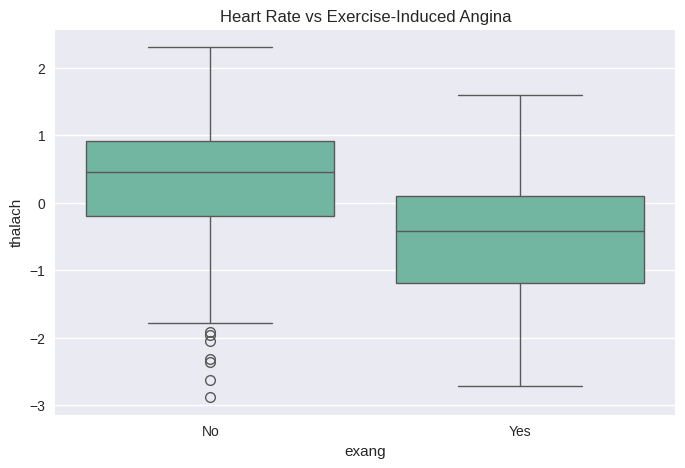

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="exang",
    y="thalach",
    data=df
)

plt.xticks([0,1],["No","Yes"])

plt.title("Heart Rate vs Exercise-Induced Angina")

plt.show()

In [ ]:
bp_gender = df.groupby("sex")["trestbps"].mean()

print(bp_gender)

sex
0    0.071133
1   -0.033149
Name: trestbps, dtype: float64


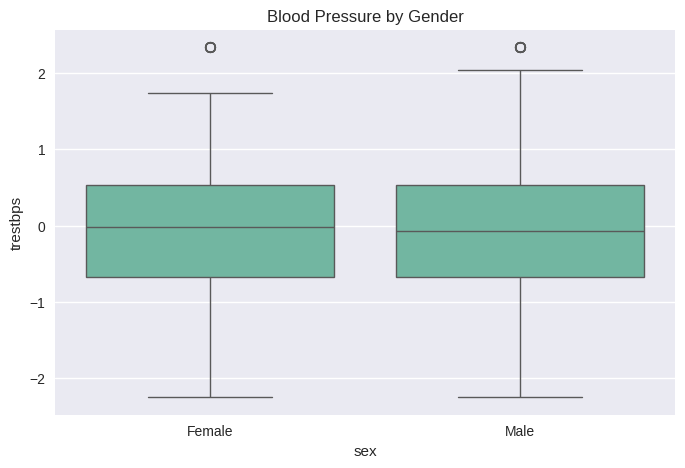

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="sex",
    y="trestbps",
    data=df
)

plt.xticks([0,1],["Female","Male"])

plt.title("Blood Pressure by Gender")

plt.show()

In [ ]:
pd.crosstab(df["fbs"], df["target"])

target,0,1
fbs,,
0,116,141
1,22,23


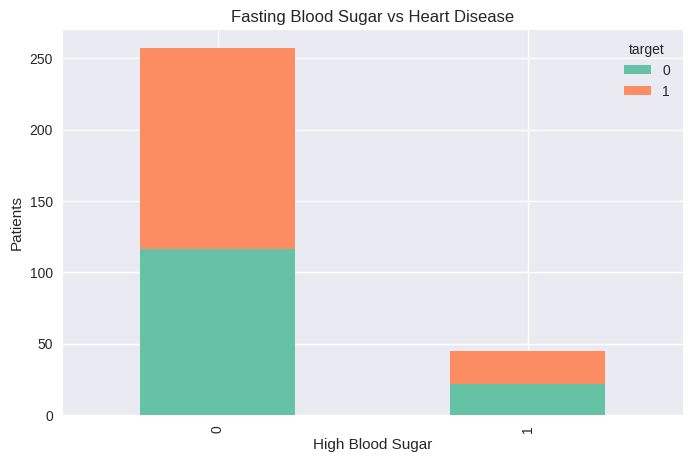

In [ ]:
pd.crosstab(
    df["fbs"],
    df["target"]
).plot(
    kind="bar",
    stacked=True,
    figsize=(8,5)
)

plt.title("Fasting Blood Sugar vs Heart Disease")
plt.xlabel("High Blood Sugar")
plt.ylabel("Patients")

plt.show()

In [ ]:
pd.crosstab(df["ca"], df["target"])

target,0,1
ca,,
0,45,130
1,44,21
2,31,7
3,17,3
4,1,3


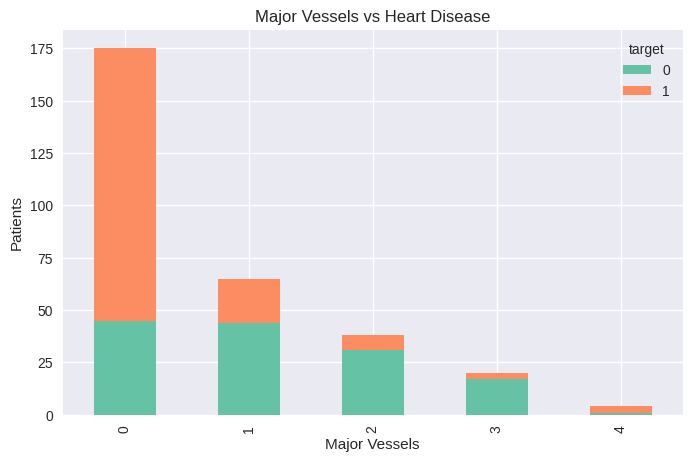

In [ ]:
pd.crosstab(
    df["ca"],
    df["target"]
).plot(
    kind="bar",
    stacked=True,
    figsize=(8,5)
)

plt.title("Major Vessels vs Heart Disease")
plt.xlabel("Major Vessels")
plt.ylabel("Patients")

plt.show()

In [ ]:
oldpeak = df.groupby("cp")["oldpeak"].mean()

print(oldpeak)

cp
0    0.292843
1   -0.642110
2   -0.199212
3    0.320051
Name: oldpeak, dtype: float64


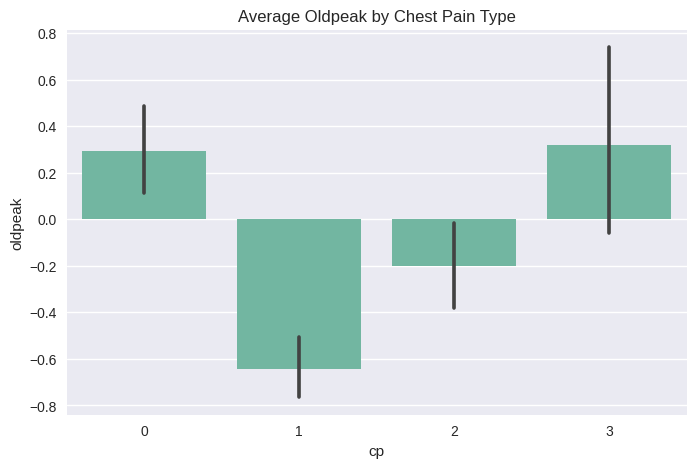

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    x="cp",
    y="oldpeak",
    data=df,
    estimator="mean"
)

plt.title("Average Oldpeak by Chest Pain Type")

plt.show()

In [ ]:
pd.crosstab(df["thal"], df["target"])

target,0,1
thal,,
0,1,1
1,12,6
2,36,129
3,89,28


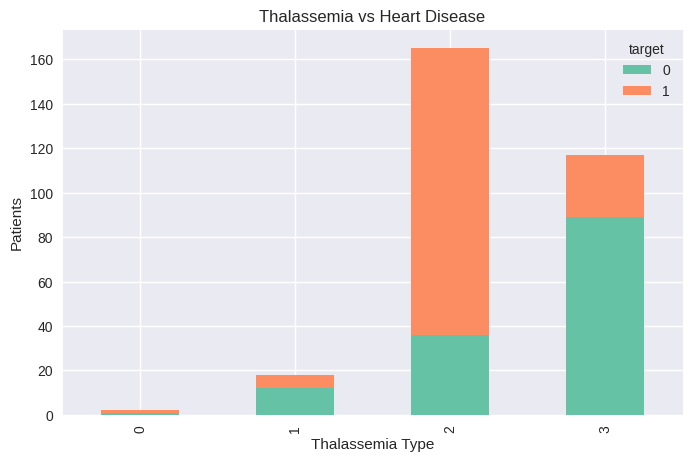

In [ ]:
pd.crosstab(
    df["thal"],
    df["target"]
).plot(
    kind="bar",
    stacked=True,
    figsize=(8,5)
)

plt.title("Thalassemia vs Heart Disease")

plt.xlabel("Thalassemia Type")

plt.ylabel("Patients")

plt.show()

In [ ]:
risk = (
    df[df["target"]==1]
    .groupby(["cp","fbs","exang","thal"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

risk.head(10)

,cp,fbs,exang,thal,Count
34,2,0,0,2,41
18,1,0,0,2,30
2,0,0,0,2,23
42,2,1,0,2,10
6,0,0,1,2,6
35,2,0,0,3,6
50,3,0,0,2,5
19,1,0,0,3,4
38,2,0,1,2,4
7,0,0,1,3,3


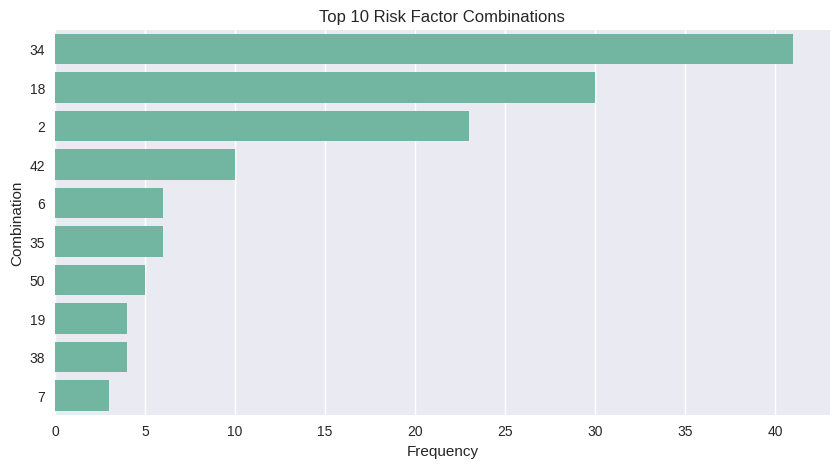

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    x="Count",
    y=risk.head(10).index.astype(str),
    data=risk.head(10)
)

plt.title("Top 10 Risk Factor Combinations")

plt.xlabel("Frequency")

plt.ylabel("Combination")

plt.show()

In [ ]:
num_cols = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

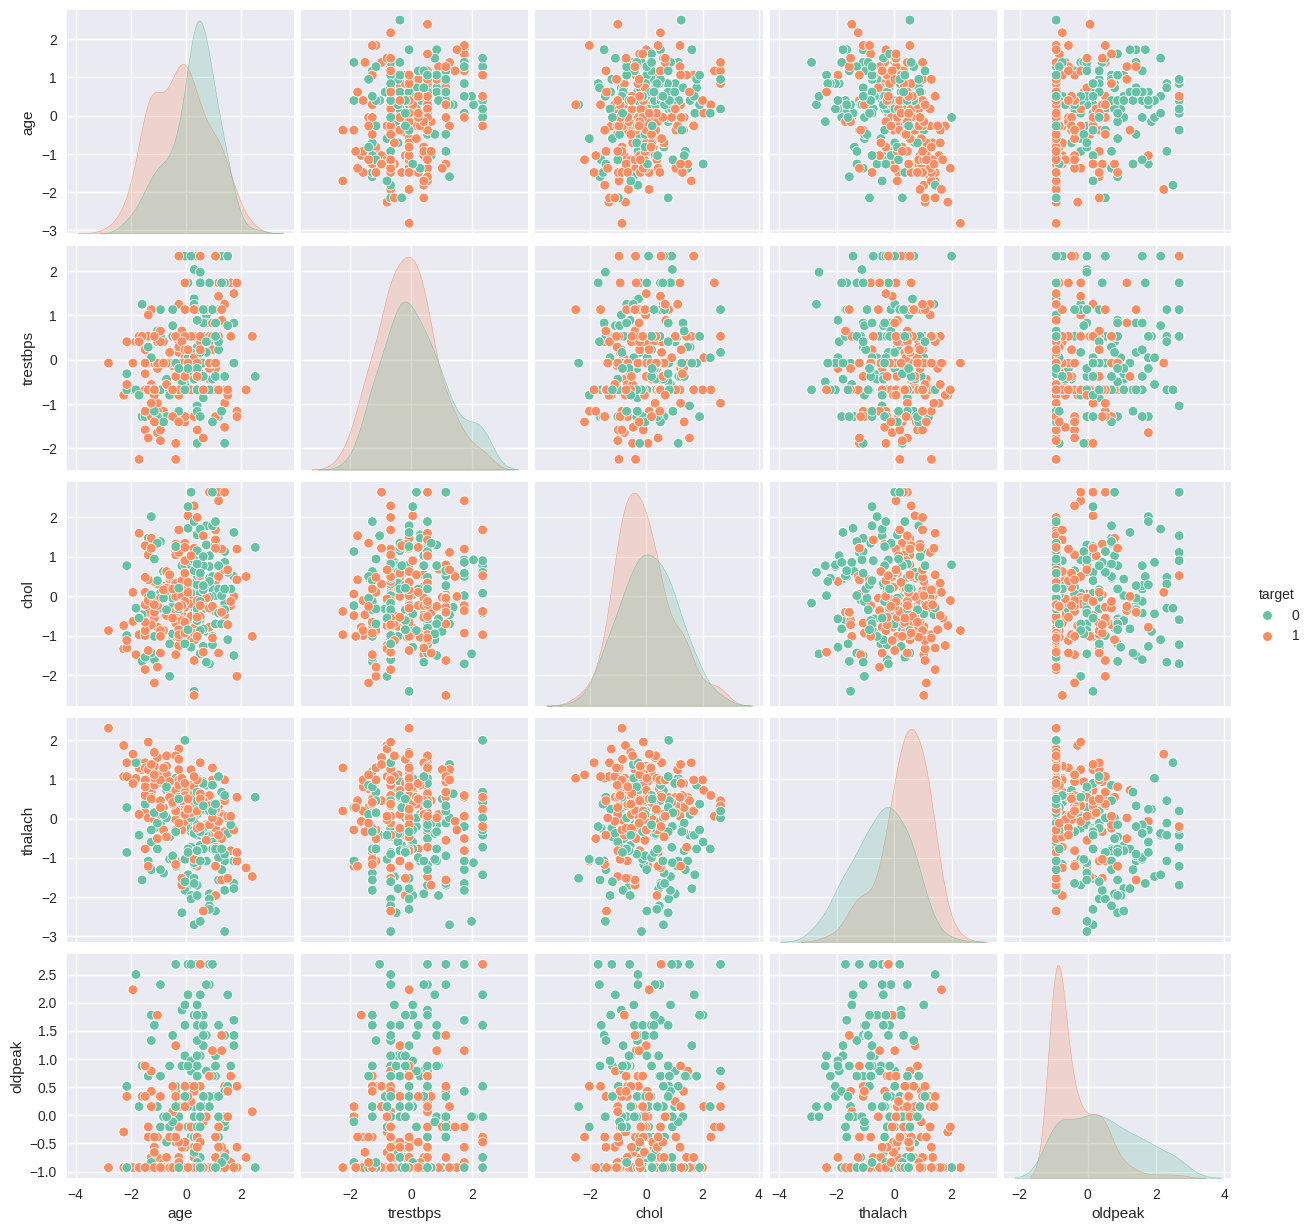

In [ ]:
sns.pairplot(
    df,
    vars=num_cols,
    hue="target",
    diag_kind="kde"
)

plt.show()

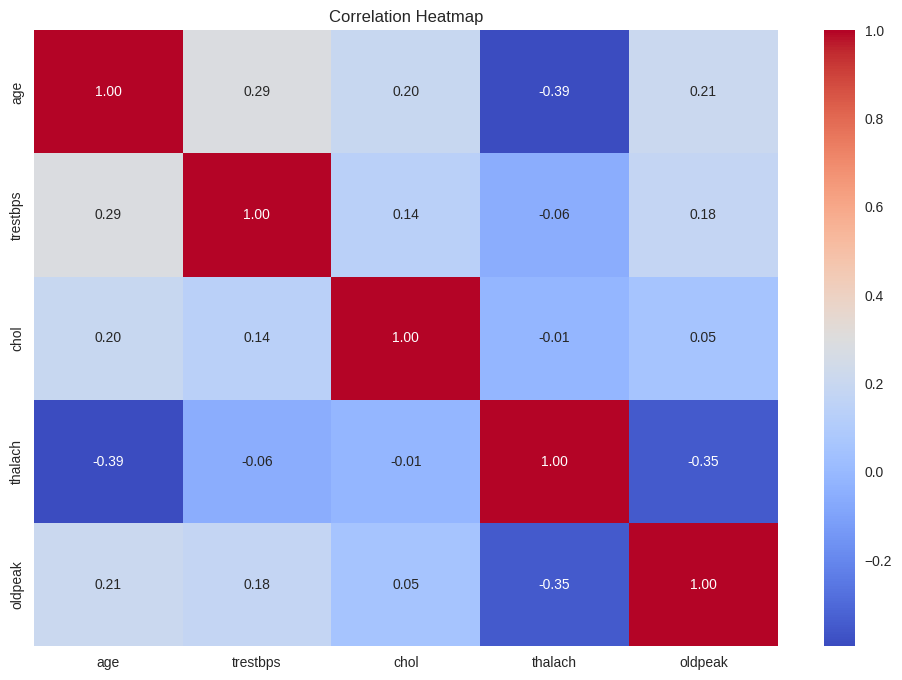

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

plt.style.use("seaborn-v0_8")
sns.set_palette("Set2")

# Load Dataset
df = pd.read_csv("heart_disease_cleaned.csv")

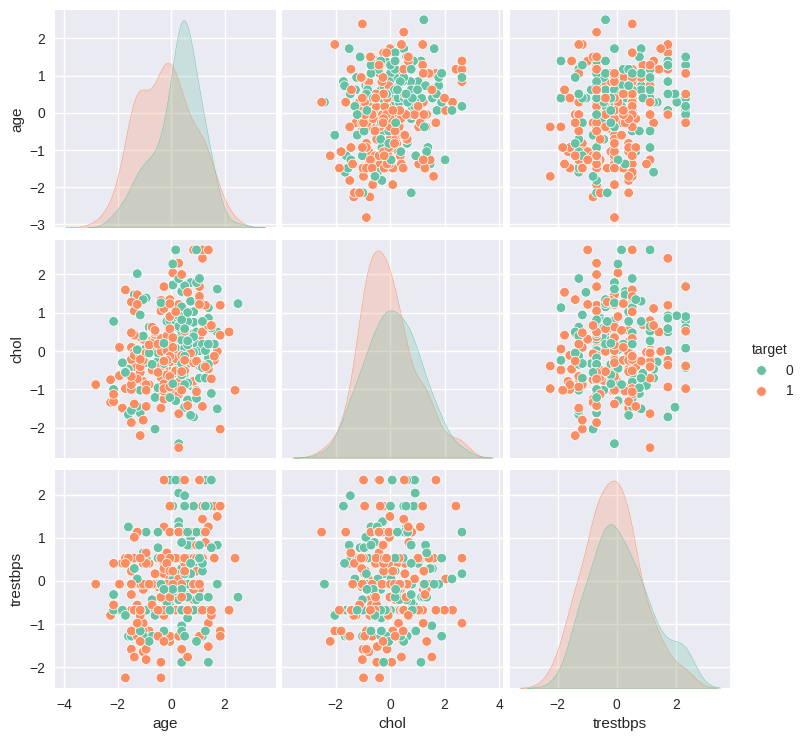

In [ ]:
sns.pairplot(
    df,
    vars=["age", "chol", "trestbps"],
    hue="target",
    diag_kind="kde"
)

plt.show()

In [ ]:
correlation = df.corr(numeric_only=True)["target"].sort_values(ascending=False)

print(correlation)

target      1.000000
cp          0.432080
thalach     0.420408
slope       0.343940
restecg     0.134874
fbs        -0.026826
chol       -0.099932
trestbps   -0.140083
age        -0.221476
sex        -0.283609
thal       -0.343101
ca         -0.408992
oldpeak    -0.435099
exang      -0.435601
Name: target, dtype: float64


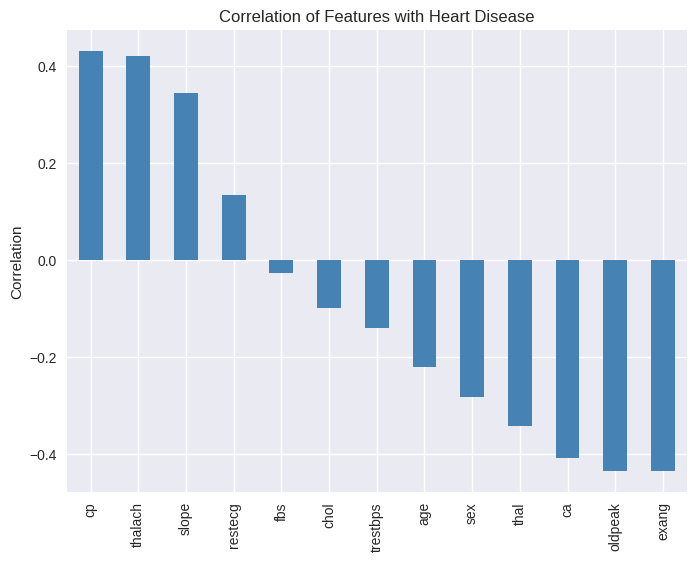

In [ ]:
plt.figure(figsize=(8,6))

correlation.drop("target").plot(
    kind="bar",
    color="steelblue"
)

plt.title("Correlation of Features with Heart Disease")
plt.ylabel("Correlation")

plt.show()

In [ ]:
X = df.drop("target", axis=1)
y = df["target"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
prediction = model.predict(X_test)

In [ ]:
accuracy = accuracy_score(y_test, prediction)

print("Model Accuracy:", round(accuracy*100,2), "%")

Model Accuracy: 75.41 %


In [ ]:
print(classification_report(y_test, prediction))

              precision    recall  f1-score   support

           0       0.81      0.69      0.75        32
           1       0.71      0.83      0.76        29

    accuracy                           0.75        61
   macro avg       0.76      0.76      0.75        61
weighted avg       0.76      0.75      0.75        61



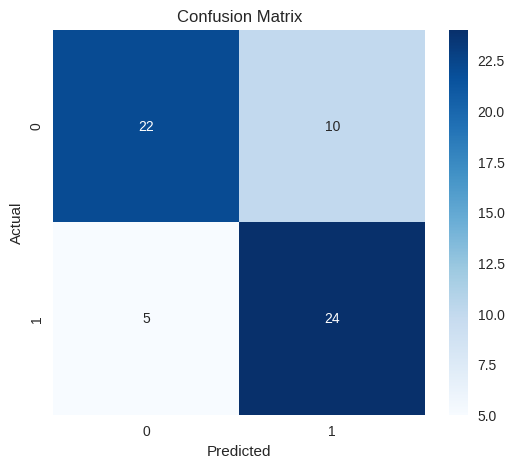

In [ ]:
cm = confusion_matrix(y_test, prediction)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

importance = importance.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

importance

,Feature,Coefficient
2,cp,1.009944
1,sex,-0.865769
9,oldpeak,-0.779500
11,ca,-0.591995
3,trestbps,-0.535720
6,restecg,0.487004
7,thalach,0.470894
12,thal,-0.390010
10,slope,0.326354
8,exang,-0.280678


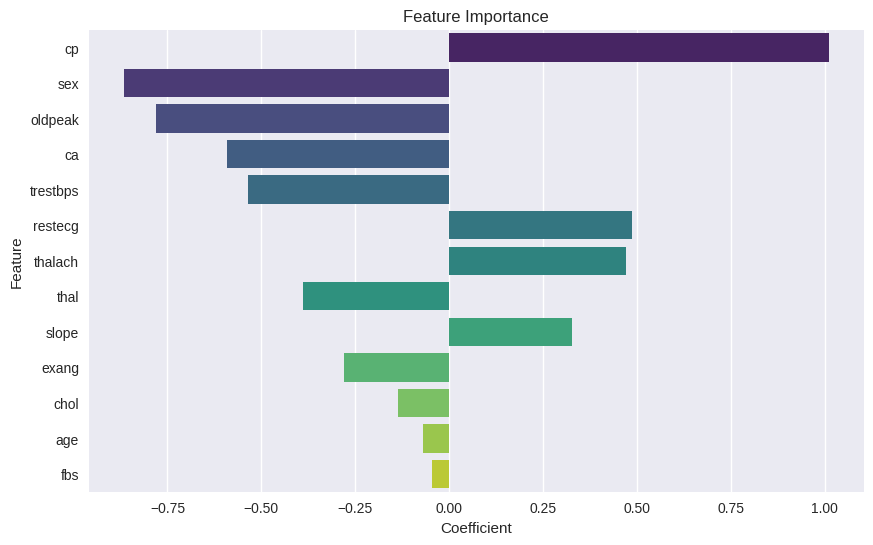

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importance,
    x="Coefficient",
    y="Feature",
    palette="viridis"
)

plt.title("Feature Importance")

plt.show()

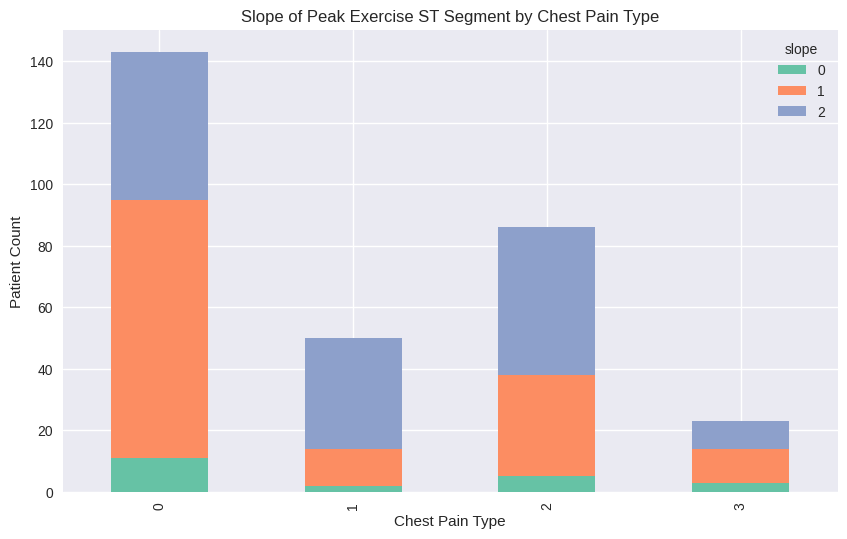

In [ ]:
pd.crosstab(
    df["cp"],
    df["slope"]
).plot(
    kind="bar",
    stacked=True,
    figsize=(10,6)
)

plt.title("Slope of Peak Exercise ST Segment by Chest Pain Type")
plt.xlabel("Chest Pain Type")
plt.ylabel("Patient Count")

plt.show()

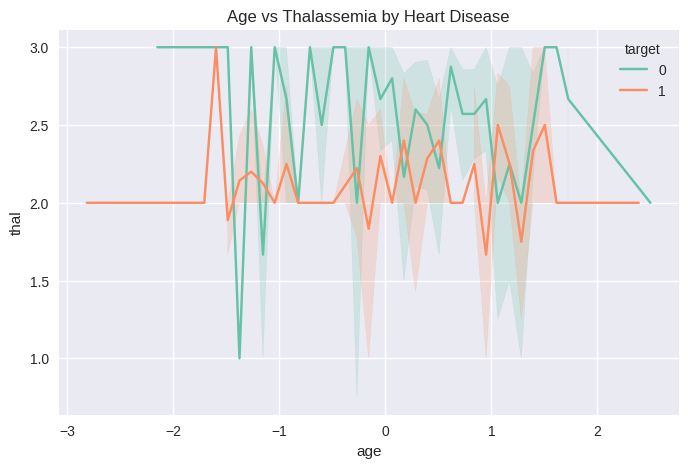

In [ ]:
plt.figure(figsize=(8,5))

sns.lineplot(
    data=df,
    x="age",
    y="thal",
    hue="target"
)

plt.title("Age vs Thalassemia by Heart Disease")

plt.show()

In [ ]:
print("="*60)
print("HEART DISEASE ANALYSIS SUMMARY")
print("="*60)

print("Total Patients :", len(df))
print("Average Age :", round(df["age"].mean(),2))
print("Average Cholesterol :", round(df["chol"].mean(),2))
print("Average Blood Pressure :", round(df["trestbps"].mean(),2))
print("Heart Disease Cases :", df["target"].sum())
print("Healthy Patients :", len(df)-df["target"].sum())
print("Prediction Accuracy :", round(accuracy*100,2),"%")

HEART DISEASE ANALYSIS SUMMARY
Total Patients : 302
Average Age : -0.0
Average Cholesterol : -0.0
Average Blood Pressure : 0.0
Heart Disease Cases : 164
Healthy Patients : 138
Prediction Accuracy : 75.41 %


Final Business Recommendations
Increase routine heart disease screening for middle-aged and older adults.
Prioritize patients with high cholesterol, high blood pressure, abnormal ECG results, and exercise-induced angina.
Use predictive models like Logistic Regression to support early risk identification.
Promote lifestyle interventions such as healthier diets, smoking cessation, and regular physical activity.
Continuously update predictive models as more patient data becomes available.